### 1. Visão Geral das 10 Classes

Amostra visual de uma imagem de cada uma das 10 classes selecionadas do dataset **NWPU-RESISC45**, permitindo observar características como textura, cor, relevo e organização espacial.

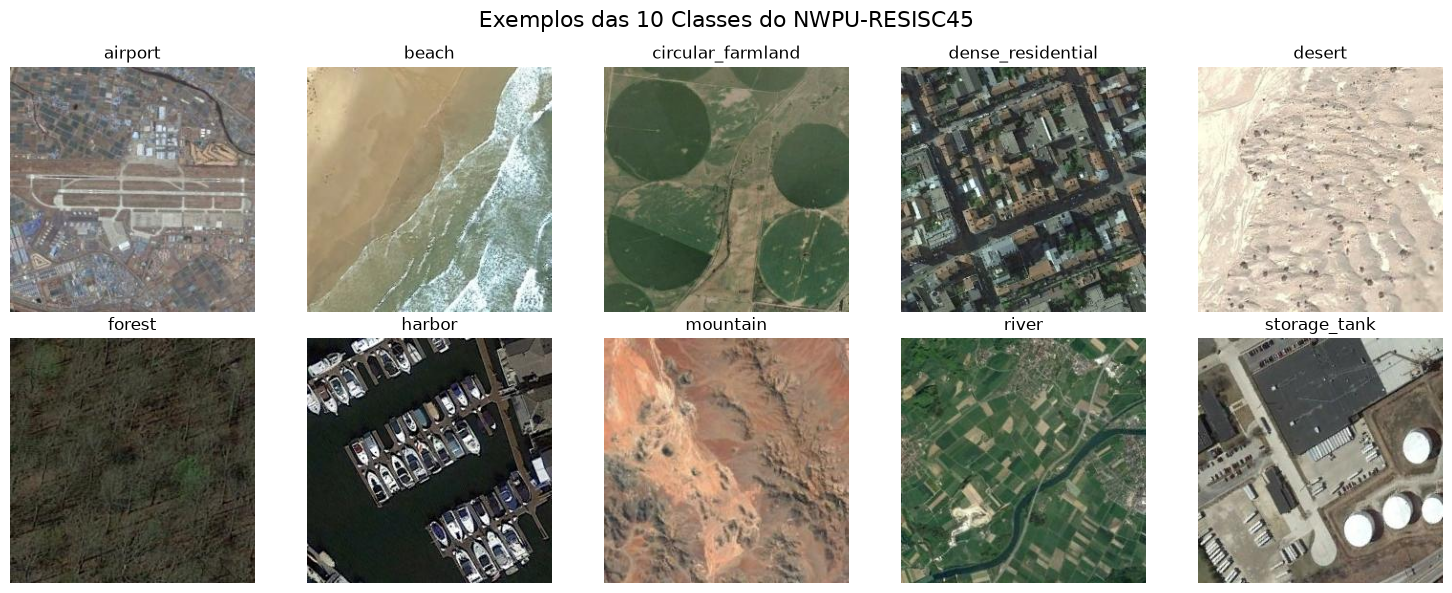

In [44]:
import math
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

# Configurações de caminhos
project_root = Path().resolve().parent
csv_path = project_root / "resultados" / "inventario_dados.csv"
raw_dir = project_root / "dados" / "raw"

# Carregar o inventário filtrando apenas imagens válidas
df = pd.read_csv(csv_path)
df_valid = df[df["status_leitura"] == "ok"]

# Sortear 1 imagem por classe
amostras = df_valid.groupby("classe").sample(n=1, random_state=42)

# Plotar o painel 2x5
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
fig.suptitle("Exemplos das 10 Classes do NWPU-RESISC45", fontsize=16)

for ax, (_, row) in zip(axes.flatten(), amostras.iterrows()):
    img_path = raw_dir.parent.parent / row["caminho_relativo"]
    img = Image.open(img_path)
    
    ax.imshow(img)
    ax.set_title(row["classe"])
    ax.axis("off")

plt.tight_layout()
plt.show()

### 2. Possíveis Ambiguidades Visuais

Exemplos de pares de classes com potencial confusão visual. Essas ambiguidades são baseadas em suposições de nós, autores, ao reconhecer certa semelhança visual nessas imagens. Hipótese que ainda deverá ser investigada após o treinamento dos modelos para verificar se haverá de fato correlação de confusão entre essas classes.

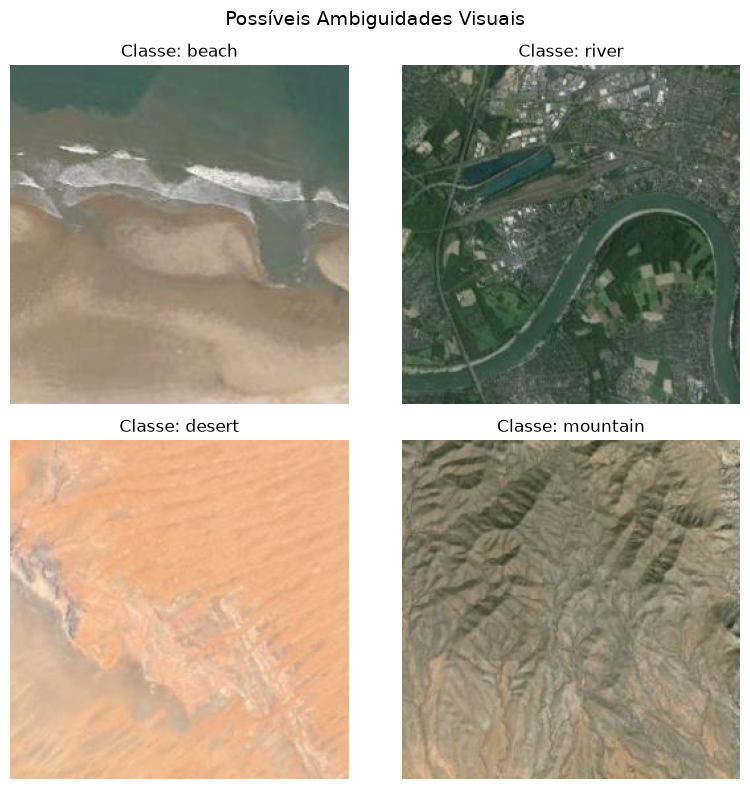

In [45]:
# Pares de classes que podem gerar confusão
pares_ambiguos = [("beach", "river"), ("desert", "mountain")]

fig, axes = plt.subplots(len(pares_ambiguos), 2, figsize=(8, 4 * len(pares_ambiguos)))
fig.suptitle("Possíveis Ambiguidades Visuais", fontsize=14)

for i, (classe_a, classe_b) in enumerate(pares_ambiguos):
    # Sorteia uma imagem de cada classe
    img_a_row = df_valid[df_valid["classe"] == classe_a].sample(n=1, random_state=24).iloc[0]
    img_b_row = df_valid[df_valid["classe"] == classe_b].sample(n=1, random_state=24).iloc[0]
    
    img_a = Image.open(raw_dir.parent.parent / img_a_row["caminho_relativo"])
    img_b = Image.open(raw_dir.parent.parent / img_b_row["caminho_relativo"])
    
    axes[i, 0].imshow(img_a)
    axes[i, 0].set_title(f"Classe: {classe_a}")
    axes[i, 0].axis("off")
    
    axes[i, 1].imshow(img_b)
    axes[i, 1].set_title(f"Classe: {classe_b}")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

### 3. Comparativo de Resolução (128 × 128 vs. 256 × 256)

Comparação visual da mesma cena nas resoluções utilizadas nos experimentos obrigatórios, evidenciando a perda de detalhes espaciais ao reduzir a imagem de `256 × 256` para `128 × 128` pixels.

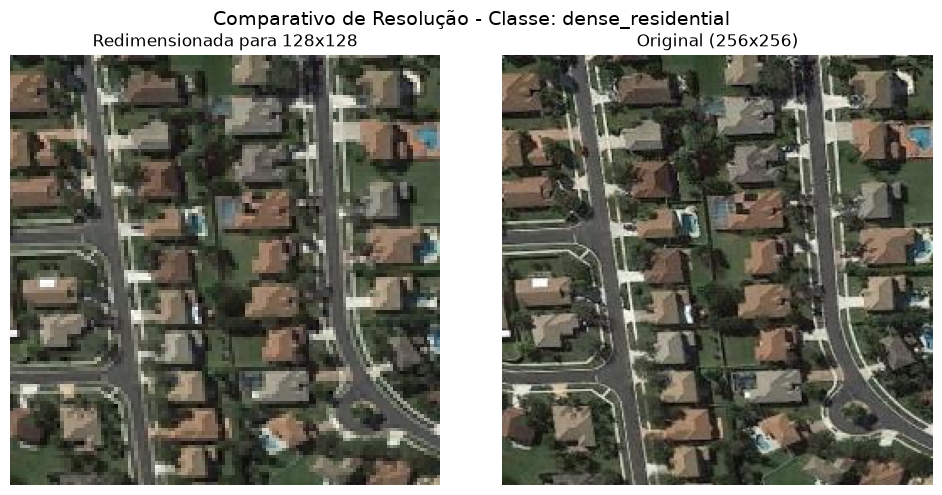

In [ ]:
exemplo_row = df_valid[df_valid["classe"] == "dense_residential"].sample(n=1, random_state=42).iloc[0]
img_path = raw_dir.parent.parent / exemplo_row["caminho_relativo"]

img_original = Image.open(img_path) # Original 256x256

img_128 = img_original.resize((128, 128), Image.Resampling.LANCZOS)

# Plotar o comparativo
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
fig.suptitle(f"Comparativo de Resolução - Classe: {exemplo_row['classe']}", fontsize=14)

axes[0].imshow(img_128)
axes[0].set_title("Redimensionada para 128x128")
axes[0].axis("off")

axes[1].imshow(img_original)
axes[1].set_title("Original (256x256)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

### 4. Auditoria de Arquivos Duplicados

Análise da proporção de imagens únicas versus duplicadas (mesmo hash MD5) e sua distribuição por classe, etapa essencial para evitar vazamento de dados entre os conjuntos de treino, validação e teste.

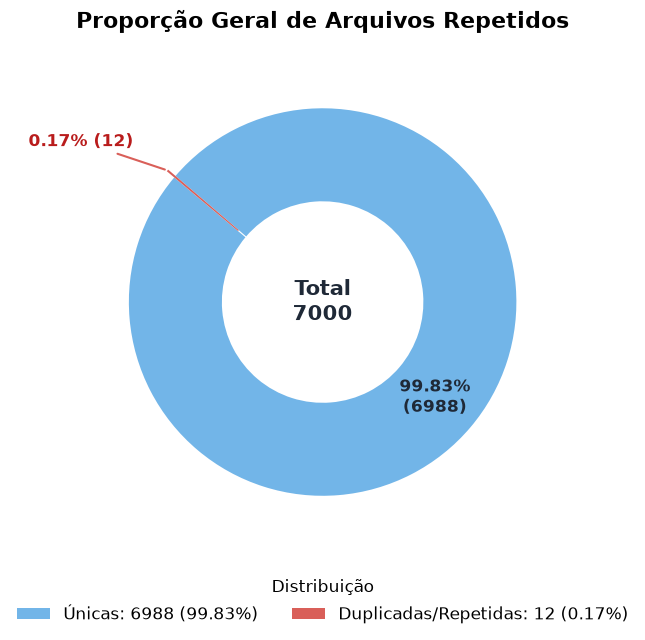

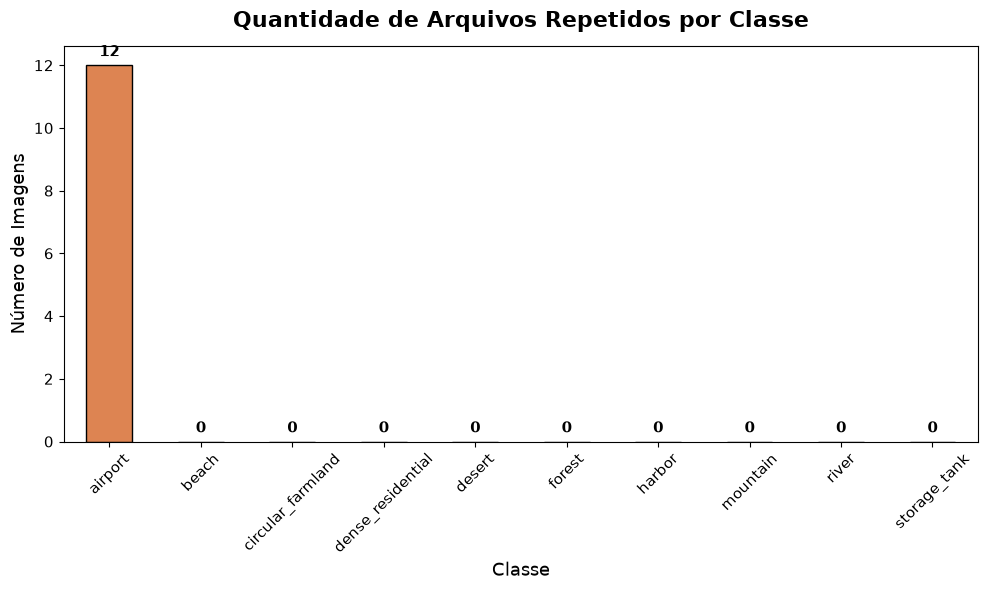

In [47]:
# Identificar duplicatas (marca todas as linhas que têm o mesmo hash)
duplicatas = df_valid["hash_md5"].duplicated(keep=False)
df_duplicadas = df_valid[duplicatas]

total_validas = len(df_valid)
total_duplicadas = len(df_duplicadas)
total_unicas = total_validas - total_duplicadas

# Gráfico 1: Proporção de Únicas vs Duplicadas (imagem separada)
valores = [total_unicas, total_duplicadas]
categorias = ["Únicas", "Duplicadas/Repetidas"]
cores = ["#72B5E8", "#D95F59"]

legend_labels = [
    f"{cat}: {val} ({(val / total_validas * 100) if total_validas else 0:.2f}%)"
    for cat, val in zip(categorias, valores)
]

def format_pct(pct: float) -> str:
    count = int(round(pct / 100.0 * total_validas))
    return f"{pct:.2f}%\n({count})" if pct >= 5 else ""

fig1, ax1 = plt.subplots(figsize=(9, 6.5))
wedges, _, autotexts = ax1.pie(
    valores,
    autopct=format_pct,
    pctdistance=0.76,
    colors=cores,
    startangle=140,
    explode=(0, 0.05),
    wedgeprops={"width": 0.48},
    textprops={"fontsize": 12, "fontweight": "bold", "color": "#1F2937"},
)
if total_duplicadas > 0:
    pct_dup = (total_duplicadas / total_validas * 100) if total_validas else 0
    ang_rad = math.radians((wedges[1].theta2 + wedges[1].theta1) / 2.0)
    x_edge = wedges[1].center[0] + wedges[1].r * math.cos(ang_rad)
    y_edge = wedges[1].center[1] + wedges[1].r * math.sin(ang_rad)
    x_text = 1.28 * math.cos(ang_rad)
    y_text = 1.28 * math.sin(ang_rad)
    ax1.annotate(
        f"{pct_dup:.2f}% ({total_duplicadas})",
        xy=(x_edge, y_edge),
        xytext=(x_text, y_text),
        ha="left" if x_text >= 0 else "right",
        va="center",
        fontsize=12,
        fontweight="bold",
        color="#B91C1C",
        arrowprops={"arrowstyle": "-", "color": "#D95F59", "lw": 1.5},
    )
    ax1.set_xlim(-1.55, 1.55)
    ax1.set_ylim(-1.3, 1.3)
ax1.text(
    0, 0,
    f"Total\n{total_validas}",
    ha="center", va="center",
    fontsize=15, fontweight="bold", color="#1F2937"
)
ax1.legend(
    wedges, legend_labels,
    title="Distribuição",
    title_fontsize=12,
    fontsize=12,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.02),
    ncol=2,
    frameon=False,
)
ax1.set_title("Proporção Geral de Arquivos Repetidos", fontsize=16, fontweight="bold", pad=16)
plt.tight_layout()
plt.show()

# Gráfico 2: Duplicadas por Classe (imagem separada)
fig2, ax2 = plt.subplots(figsize=(10, 6))
if total_duplicadas > 0:
    duplicadas_por_classe = df_duplicadas["classe"].value_counts()
    
    todas_classes = df_valid["classe"].unique()
    duplicadas_por_classe = duplicadas_por_classe.reindex(todas_classes, fill_value=0).sort_values(ascending=False)
    
    duplicadas_por_classe.plot(kind="bar", color="#DD8452", edgecolor="black", ax=ax2)
    ax2.set_title("Quantidade de Arquivos Repetidos por Classe", fontsize=16, fontweight="bold", pad=14)
    ax2.set_ylabel("Número de Imagens", fontsize=13)
    ax2.set_xlabel("Classe", fontsize=13)
    ax2.tick_params(axis="x", rotation=45, labelsize=11)
    ax2.tick_params(axis="y", labelsize=11)
    
    for p in ax2.patches:
        height = p.get_height()
        ax2.annotate(
            f"{int(height)}",
            (p.get_x() + p.get_width() / 2, height),
            ha="center", va="bottom",
            xytext=(0, 4), textcoords="offset points",
            fontsize=11, fontweight="bold"
        )
else:
    ax2.text(0.5, 0.5, "Nenhuma duplicata encontrada no dataset.", ha="center", va="center", fontsize=13)
    ax2.set_title("Quantidade de Arquivos Repetidos por Classe", fontsize=16, fontweight="bold", pad=14)
    ax2.axis("off")

plt.tight_layout()
plt.show()